# exp01 — сезонность × погода × ликвидность: разбор результатов

Протокол и критерии зафиксированы в [README.md](README.md) до прогона. Журнал проблем — [PROBLEMS.md](PROBLEMS.md).
Ноутбук читает готовые результаты (`results/`), поэтому исполняется за секунды; пересчет — `run_study.py`.

In [1]:
import json, sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "backtest_strat").is_dir())
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(ROOT / "research/exp01_seasonal_weather_liquidity"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.width", 200)
RES = ROOT / "research/exp01_seasonal_weather_liquidity/results"
sc = pd.read_csv(RES / "asset_scorecard.csv", index_col=0)
quality = pd.read_csv(RES / "data_quality.csv", index_col=0)
params = json.loads((RES / "params.json").read_text())
print("период:", params["start"], "→", params["end"], "| активов:", len(sc), "| часов на актив:", int(sc.hours.median()))

период: 2024-01-01 → 2024-06-29 | активов: 16 | часов на актив: 3624


## 1. Качество данных (до любых выводов)

In [2]:
quality[["days_validated", "days_ok", "days_warn", "days_fail", "missing_days"]].T

symbol,BTC-USDT,ETH-USDT,SOL-USDT,XRP-USDT,DOGE-USDT,LTC-USDT,ADA-USDT,AVAX-USDT,LINK-USDT,DOT-USDT,ATOM-USDT,ETC-USDT,BCH-USDT,UNI-USDT,FIL-USDT,TRX-USDT
days_validated,181,181,181,181,181,181,181,181,181,181,181,181,181,181,181,181
days_ok,179,180,178,180,176,179,180,180,181,180,181,179,180,180,181,181
days_warn,2,1,3,1,5,2,1,1,0,1,0,2,1,1,0,0
days_fail,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
missing_days,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Все 16 активов × 181 день проверены, FAIL и пропущенных дней нет; WARN (0–5 дней на актив) — реальные события рынка
(например, обвал 3 января), а не дефекты данных. Данные пригодны для анализа.

## 2. Калибровка тестов — обязательный шаг до интерпретации

На синтетике с известной истиной проверено, **умеет ли тест видеть эффект и не выдумывает ли его**.
Первая версия теста сезонности (циклический сдвиг сигнала) на этом шаге оказалась «слепой»: мощность 0 при эффекте 15 б.п.
(PROBLEMS.md, P12). Ниже — финальные тесты.

In [3]:
cal = json.loads((RES / "calibration.json").read_text())
rows = []
for test, d in cal.items():
    for kind, scen in d.items():
        for name, r in scen.items():
            rows.append({"тест": test, "вид": kind, "сценарий": name, "p<0.05": r["rejects_p05"], "p<0.10": r["rejects_p10"]})
pd.DataFrame(rows).set_index(["тест", "вид", "сценарий"])

p<0.05  p<0.10
тест        вид                 сценарий                                    
edge_ttest  ложные срабатывания случайное блуждание             0.05    0.10
                                дрейф 3 б.п./ч                  0.05    0.10
                                кластеры волатильности          0.05    0.09
                                дрейф + кластеры                0.04    0.08
            мощность            5 б.п. в 4 часах из 24          0.06    0.11
                                15 б.п. в 4 часах из 24         0.65    0.75
                                30 б.п. в 4 часах из 24         1.00    1.00
selectivity ложные срабатывания случайное блуждание             0.07    0.13
                                дрейф 3 б.п./ч                  0.06    0.12
                                кластеры волатильности          0.04    0.09
                                дрейф + кластеры                0.03    0.10
            мощность            фильтр добавляет 10 б.п./час    0.77    0.86
                                фильтр добавляет 25 б.п./час    1.00    1.00

**Как читать:** в «ложных срабатываниях» значения должны быть ≈ 0.05 / 0.10 (так и есть); в «мощности» — как можно ближе к 1.
Эффект в 15 б.п. в 4 часах суток обнаруживается в ~60% случаев, 30 б.п. — в ~100%: мощность достаточна, чтобы увидеть
эффект, способный покрыть издержки (≈ 20 б.п. на круг при taker 10 б.п.).

## 3. Сезонность (M0): есть ли что-то у какого-то актива

In [4]:
a = sc[["edge_bps", "edge_t", "edge_p", "edge_q", "M0_gross_bps_h1", "M0_gross_bps_h2", "active_hours"]].copy()
a["same_sign_Q1_Q2"] = np.sign(a.M0_gross_bps_h1) == np.sign(a.M0_gross_bps_h2)
a["passes"] = (a.edge_bps > 0) & (a.edge_q < 0.10) & a.same_sign_Q1_Q2
print("активов, прошедших критерий (edge > 0, q < 0.10, одинаковый знак в Q1 и Q2):", int(a.passes.sum()), "из", len(a))
a.sort_values("edge_p")

активов, прошедших критерий (edge > 0, q < 0.10, одинаковый знак в Q1 и Q2): 0 из 16


,edge_bps,edge_t,edge_p,edge_q,M0_gross_bps_h1,M0_gross_bps_h2,active_hours,same_sign_Q1_Q2,passes
symbol,,,,,,,,,
ETC-USDT,-6.23,-2.12,0.03,0.43,-1.61,-2.19,1137,True,False
LTC-USDT,-3.80,-1.93,0.05,0.43,-1.71,-0.94,1188,True,False
TRX-USDT,1.76,1.73,0.08,0.44,1.77,-0.01,1455,False,False
BCH-USDT,-4.88,-1.29,0.20,0.54,-1.52,-1.34,1050,True,False
DOGE-USDT,-6.10,-1.26,0.21,0.54,-5.04,0.54,1018,False,False
BTC-USDT,2.34,1.11,0.27,0.54,-0.54,1.51,1053,False,False
ADA-USDT,-2.77,-1.07,0.28,0.54,-0.59,-1.09,1163,True,False
AVAX-USDT,-3.64,-1.04,0.30,0.54,-1.16,-1.15,1146,True,False
LINK-USDT,-2.90,-0.99,0.32,0.54,-1.27,-0.71,1175,True,False


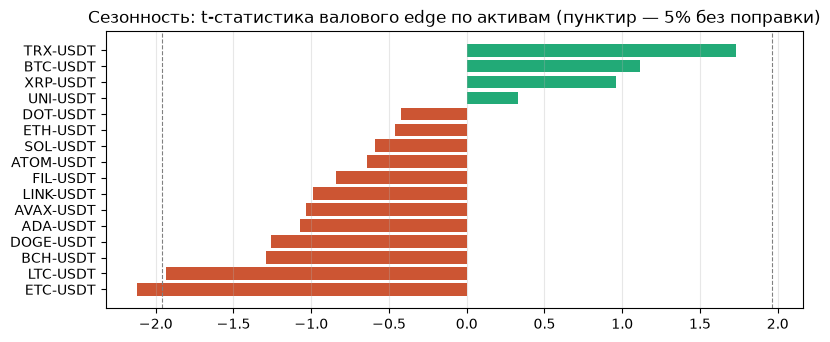

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
s = sc.sort_values("edge_t")
ax.barh(s.index, s.edge_t, color=np.where(s.edge_t > 0, "#2a7", "#c53"))
for x in (-1.96, 1.96): ax.axvline(x, ls="--", c="gray", lw=.8)
ax.set_title("Сезонность: t-статистика валового edge по активам (пунктир — 5% без поправки)"); ax.grid(alpha=.3, axis="x")

Ни один актив не проходит критерий. У 12 из 16 активов знак edge **отрицательный** (в среднем −1.9 б.п.): «повторять
профиль того же часа» хуже нуля. Но активы сильно коррелируют (среднее попарных корреляций дневных вкладов ≈ 0.37), поэтому
эффективно это не 12 независимых наблюдений; общий тест по активам — t ≈ −1.0, значимости нет. Это **наблюдение для новой,
заранее зафиксированной гипотезы на другом периоде**, а не находка.

## 4. Погода и ликвидность: улучшают ли фильтры отбор часов

In [6]:
b = sc[["weather_selectivity_bps", "weather_selectivity_p", "weather_selectivity_q", "reg_t_weather",
        "liq_selectivity_bps", "liq_selectivity_p", "liq_selectivity_q", "reg_t_liq"]]
print("сырых p<0.05 из 48 тестов (сезонность+погода+ликвидность):",
      int((sc.edge_p < .05).sum() + (sc.weather_selectivity_p < .05).sum() + (sc.liq_selectivity_p < .05).sum()),
      "| случайно ожидалось ≈", round(0.05 * 48, 1))
print("минимальные q:  погода %.2f | ликвидность %.2f" % (b.weather_selectivity_q.min(), b.liq_selectivity_q.min()))
b.sort_values("weather_selectivity_p")

сырых p<0.05 из 48 тестов (сезонность+погода+ликвидность): 4 | случайно ожидалось ≈ 2.4
минимальные q:  погода 0.32 | ликвидность 0.29


,weather_selectivity_bps,weather_selectivity_p,weather_selectivity_q,reg_t_weather,liq_selectivity_bps,liq_selectivity_p,liq_selectivity_q,reg_t_liq
symbol,,,,,,,,
BTC-USDT,9.76,0.02,0.32,1.28,1.21,0.68,0.83,-0.69
XRP-USDT,-11.85,0.05,0.43,-1.26,8.41,0.21,0.66,-2.04
BCH-USDT,10.08,0.26,0.98,-0.16,3.70,0.57,0.83,1.31
TRX-USDT,2.33,0.32,0.98,-0.82,-2.61,0.29,0.78,1.99
ETH-USDT,4.54,0.44,0.98,0.05,-1.13,0.78,0.84,-0.12
DOT-USDT,4.09,0.52,0.98,-0.75,-7.59,0.07,0.36,1.26
AVAX-USDT,4.94,0.56,0.98,0.85,2.44,0.78,0.84,-0.80
FIL-USDT,3.57,0.63,0.98,-0.20,-4.80,0.42,0.83,1.51
ADA-USDT,3.05,0.67,0.98,-0.83,3.54,0.56,0.83,-0.30


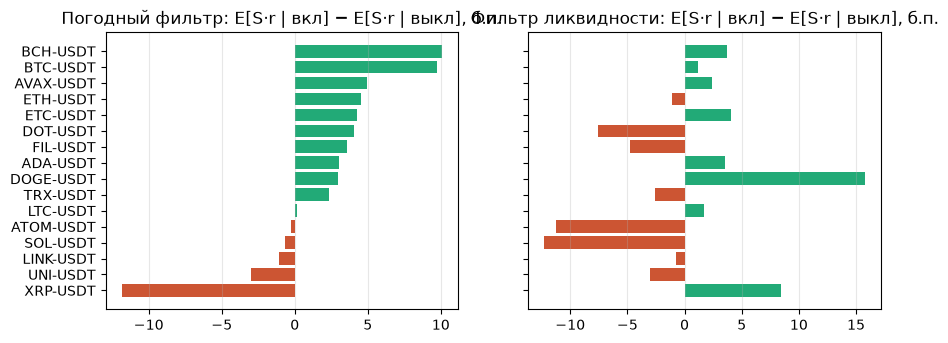

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a_, (col, title) in zip(ax, [("weather_selectivity_bps", "Погодный фильтр"), ("liq_selectivity_bps", "Фильтр ликвидности")]):
    s = sc.sort_values(col); a_.barh(s.index, s[col], color=np.where(s[col] > 0, "#2a7", "#c53"))
    a_.set_title(title + ": E[S·r | вкл] − E[S·r | выкл], б.п."); a_.grid(alpha=.3, axis="x")

**Механика ложных находок — наглядно.** У BTC погодный фильтр «улучшает» отбор часов (+9.8 б.п., сырой p ≈ 0.02), а у XRP то же
самое с **обратным знаком** (−11.9 б.п., p ≈ 0.05). Поверхностно это два «значимых» результата; после поправки на 16 активов
(q ≈ 0.3) и с учетом противоположных знаков — шум. Без FDR-поправки и предрегистрации сюда легко дописать «погода работает на BTC».

## 5. Издержки: что остается после комиссий

In [8]:
v = ["M0", "M1", "M2", "M3"]
net10 = pd.DataFrame({k: sc[f"{k}_net_pnl_usd"] for k in v})
net2 = pd.DataFrame({k: sc[f"{k}_net_low_fee_pnl_usd"] for k in v})
gross = pd.DataFrame({k: sc[f"{k}_gross_bps_per_hour"] for k in v})
print("комбинаций актив×вариант:", net10.size)
print("PnL < 0 при taker 10 б.п.:", int((net10 < 0).sum().sum()), "| при 2 б.п.:", int((net2 < 0).sum().sum()))
pd.concat({"чистый PnL, USDT (10 б.п.)": net10, "чистый PnL, USDT (2 б.п.)": net2}, axis=1)

комбинаций актив×вариант: 64
PnL < 0 при taker 10 б.п.: 64 | при 2 б.п.: 63


чистый PnL, USDT (10 б.п.)                             чистый PnL, USDT (2 б.п.)                          
                                  M0        M1        M2      M3                        M0      M1        M2      M3
symbol                                                                                                              
BTC-USDT                   -1,637.48   -245.40 -1,000.47 -259.54                   -132.68  162.60    -52.47  -19.54
ETH-USDT                   -2,063.82   -453.92 -1,358.21 -300.58                   -491.82  -31.52   -346.21  -49.38
SOL-USDT                   -2,104.91   -572.57 -1,595.68 -594.16                   -684.11 -196.57   -739.68 -368.56
XRP-USDT                   -2,433.89 -1,028.25 -1,350.05 -691.50                   -573.89 -519.45    -94.85 -305.90
DOGE-USDT                  -2,679.35   -618.12 -1,481.89 -347.80                 -1,174.55 -240.52   -457.09  -74.20
LTC-USDT                   -2,893.86   -671.84 -1,867.94 -406.85                 -1,186.66 -271.84   -738.34 -126.85
ADA-USDT                   -2,868.45   -616.42 -1,660.95 -444.16                 -1,315.65 -248.42   -711.35 -189.76
AVAX-USDT                  -2,646.27   -540.71 -1,728.39 -405.39                 -1,107.87 -166.31   -692.39 -192.59
LINK-USDT                  -2,446.88   -656.73 -1,687.56 -450.27                   -870.88 -247.13   -612.36 -143.07
DOT-USDT                   -2,291.15   -475.86 -1,685.61 -383.93                   -645.55  -66.26   -630.41 -142.33
ATOM-USDT                  -2,843.29   -650.64 -2,017.71 -457.38                 -1,248.89 -289.04 -1,058.51 -217.38
ETC-USDT                   -2,813.56   -608.37 -1,996.86 -391.40                 -1,254.36 -219.57   -840.86 -113.00
BCH-USDT                   -3,174.27   -634.52 -2,093.25 -404.45                 -1,742.27 -255.32 -1,110.85 -132.45
UNI-USDT                   -2,302.96   -652.11 -1,658.31 -394.76                   -582.16 -216.91   -479.91 -105.16
FIL-USDT                   -2,413.70   -577.36 -1,838.05 -461.25                   -819.30 -142.16   -699.65 -115.65
TRX-USDT                   -2,116.31   -400.81 -1,371.69 -253.78                   -365.11  -21.61   -313.29  -16.98

Text(0.5, 1.0, 'Медианный по 16 активам чистый PnL на 1000 USDT за ~6 мес., USDT')

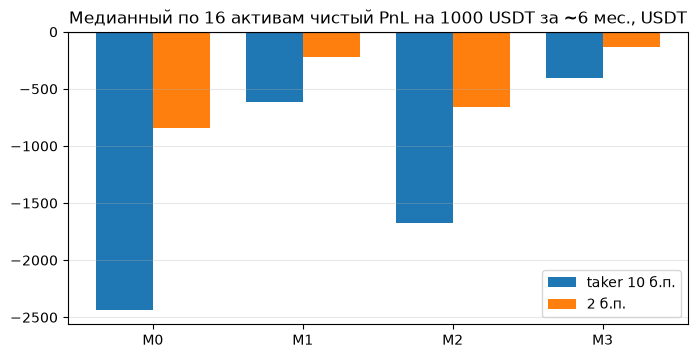

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(v)); w = 0.38
ax.bar(x - w/2, net10.median(), w, label="taker 10 б.п."); ax.bar(x + w/2, net2.median(), w, label="2 б.п.")
ax.set_xticks(x, v); ax.axhline(0, c="k", lw=.8); ax.legend(); ax.grid(alpha=.3, axis="y")
ax.set_title("Медианный по 16 активам чистый PnL на 1000 USDT за ~6 мес., USDT")

При taker 10 б.п. **отрицательны все 64** комбинации, при 2 б.п. положительна одна — BTC×M1 (+163 USDT на 1000, 451 сделка),
у которой валовый результат статистически неотличим от нуля. Фильтры (M1–M3) «улучшают» PnL почти целиком тем, что реже
торгуют и платят меньше комиссий, а не тем, что лучше выбирают часы (см. селективность в разделе 4).

## 6. Проверка механики движка: быстрая оценка против движка проекта

In [10]:
d = pd.DataFrame({k: sc[f"{k}_engine_net_pnl_usd"] - sc[f"{k}_net_pnl_usd"] for k in v})
rel = pd.DataFrame({k: d[k].abs() / sc[f"{k}_engine_fees_usd"] for k in v})
print("макс |движок − быстрая оценка|: %.1f USDT; относительно комиссий: %.1f%%" % (d.abs().max().max(), rel.max().max() * 100))
d.describe().loc[["mean", "min", "max"]]

макс |движок − быстрая оценка|: 56.6 USDT; относительно комиссий: 4.1%


,M0,M1,M2,M3
mean,18.28,5.80,10.60,3.10
min,-2.90,-4.60,-9.87,-2.81
max,56.61,16.90,50.00,12.45


Расхождение ≲ 5% комиссий. Оно систематическое (движок чуть пессимистичнее): постоянное количество вместо постоянной суммы
и округление котировок к тику. До учета тика расхождение достигало 10% (PROBLEMS.md, P11) — пример того, как независимая
вторая оценка находит упрощение в первой.

## 7. Решение по критериям из README

| Критерий | Порог | Факт | Выполнен |
|---|---|---|---|
| Сезонность: edge > 0, q < 0.10, знак совпадает в Q1/Q2 | ≥ 1 актив | 0 из 16 (мин. q = 0.43) | нет |
| Погода: selectivity > 0, q < 0.10 | ≥ 1 актив | 0 из 16 (мин. q = 0.32) | нет |
| Ликвидность: selectivity > 0, q < 0.10 | ≥ 1 актив | 0 из 16 (мин. q = 0.29) | нет |
| Торгуемость: чистый PnL > 0 при 10 и 2 б.п. | ≥ 1 актив×вариант | 0 из 64 | нет |

**Вывод: гипотеза в заданной формулировке отклонена; активов, на которых она работает, не найдено.**

**Что это означает честно, а не оптимистично:**
- Это отрицательный результат на одном периоде (янв–июн 2024), 16 активах, одной спецификации сигнала. Он не доказывает отсутствие
  сезонности вообще: часовые эффекты размером менее ~15 б.п. дизайн не обнаружит (раздел 2), а на таких размерах они и не торгуемы
  при комиссии taker.
- Погодный фактор не показал ничего, но и априорное обоснование у него было самым слабым звеном.
- Единственная нестабильность, похожая на сигнал (TRX: t ≈ 1.7, весь эффект в январе–феврале), не проходит критерий устойчивости.

**Что дальше (каждый пункт — отдельный эксперимент со своей предрегистрацией):**
1. Проверить наблюдение «знак сезонного сигнала отрицателен у 12/16» на **другом периоде** (июль–декабрь 2024) как новую гипотезу.
2. Для торгуемости нужны либо другие классы стратегий (maker, меньший оборот), либо инструменты с нулевой комиссией — иначе издержки
   доминируют над любым часовым эффектом такого масштаба.
3. Если погода интересна как фактор — для товарных/энергетических активов, где канал причинности физический.